# Esperimento M2 - Treni ad alta frequenza con e senza Kv3

**Domanda:** quanto serve Kv3 al neurone MNTB per seguire stimoli ad alta frequenza?

Riproduce:
- **Macica 2003, Figura 1d-f** (dati sperimentali): neuroni wild-type, con TEA 1 mM e knockout di Kv3.1, treni a 100–300 Hz;
- **Wang 1998, Figura 5C-D** (modello): il modello con e senza I_HT, treni a 100–400 Hz.

| Condizione | Come la simulo | Cosa rappresenta |
|---|---|---|
| Controllo | `g_Kv3` = 150 nS | neurone sano |
| Senza Kv3 | `g_Kv3` = 0 nS | blocco con TEA 1 mM o knockout di Kv3.1 |

**Stimolo:** 30 impulsi da 1.4 nA per 0.25 ms (protocollo del modello di Wang/Macica) a 100, 200, 300 e 400 Hz.

**Criterio di fallimento:** il picco della risposta resta sotto −10 mV (stesso criterio di Macica).

**Risultato atteso (Wang, Fig. 5C-D):**
- con Kv3: segue 1:1 fino a circa 300 Hz, a 400 Hz alterna spike e fallimenti;
- senza Kv3: segue fino a 200 Hz (con ampiezza che cala), sopra i 300 Hz solo il primo spike è pieno.

**Nota sul ritardo:** il generatore di corrente è collegato con ritardo `dt` (0.01 ms) invece del default di NEST (1 ms).


In [1]:
# ============================================================
# 0. SETUP: import, compilazione del modello, funzione di simulazione
# ============================================================

import os
os.environ["PYNEST_QUIET"] = "1"    # nasconde il banner di NEST

import numpy as np
import matplotlib.pyplot as plt
import nest
nest.set_verbosity("M_WARNING")    # mostra solo avvisi ed errori di NEST, non i messaggi informativi
import pynestml
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

print("NEST  :", nest.__version__)
print("NESTML:", pynestml.__version__)

# Genera il codice C++, lo compila e lo carica in NEST (circa 1 minuto)
# Passo il NOME del file e non il suo contenuto: se riceve il testo del modello, NESTML
# riscrive mntb_hh_kv3_neuron.nestml nella cartella corrente aggiungendo ogni volta
# una riga vuota in fondo (pynestml nest_code_generator_utils.py, righe 101-104).
wt_module, wt_model = NESTCodeGeneratorUtils.generate_code_for("mntb_hh_kv3_neuron.nestml")
print("Modello:", wt_model)

dt = 0.01   # ms - passo di simulazione


def run_simulation(amplitude_times, amplitude_values, sim_time, params=None):
    # Simula il neurone con una corrente a gradini e restituisce tempi (ms) e V_m (mV).
    #   amplitude_times  : istanti (ms) in cui la corrente cambia valore
    #   amplitude_values : valore della corrente (pA) a partire da ciascun istante
    #   sim_time         : durata totale della simulazione (ms)
    #   params           : parametri del neurone da cambiare, es. {"g_Kv3": 0.0}
    nest.ResetKernel()
    nest.SetKernelStatus({"resolution": dt})
    nest.Install(wt_module)

    neuron = nest.Create(wt_model, 1, params=params or {})

    stimulus = nest.Create(
        "step_current_generator",
        params={"amplitude_times": amplitude_times,
                "amplitude_values": amplitude_values},
    )
    multimeter = nest.Create("multimeter", params={"record_from": ["V_m"], "interval": dt})

    # ritardo minimo (dt) invece del default di 1 ms
    nest.Connect(stimulus, neuron, syn_spec={"delay": dt})
    nest.Connect(multimeter, neuron)

    nest.Simulate(sim_time)

    events = multimeter.get("events")
    order = np.argsort(events["times"])
    return events["times"][order], events["V_m"][order]


NEST  : 3.9.0
NESTML: 8.2.0


[ODE-toolbox] WARNING:Not preserving expression for variable "refr_t" as it is solved by propagator solver


Modello: mntb_hh_kv3_neuron_nestml


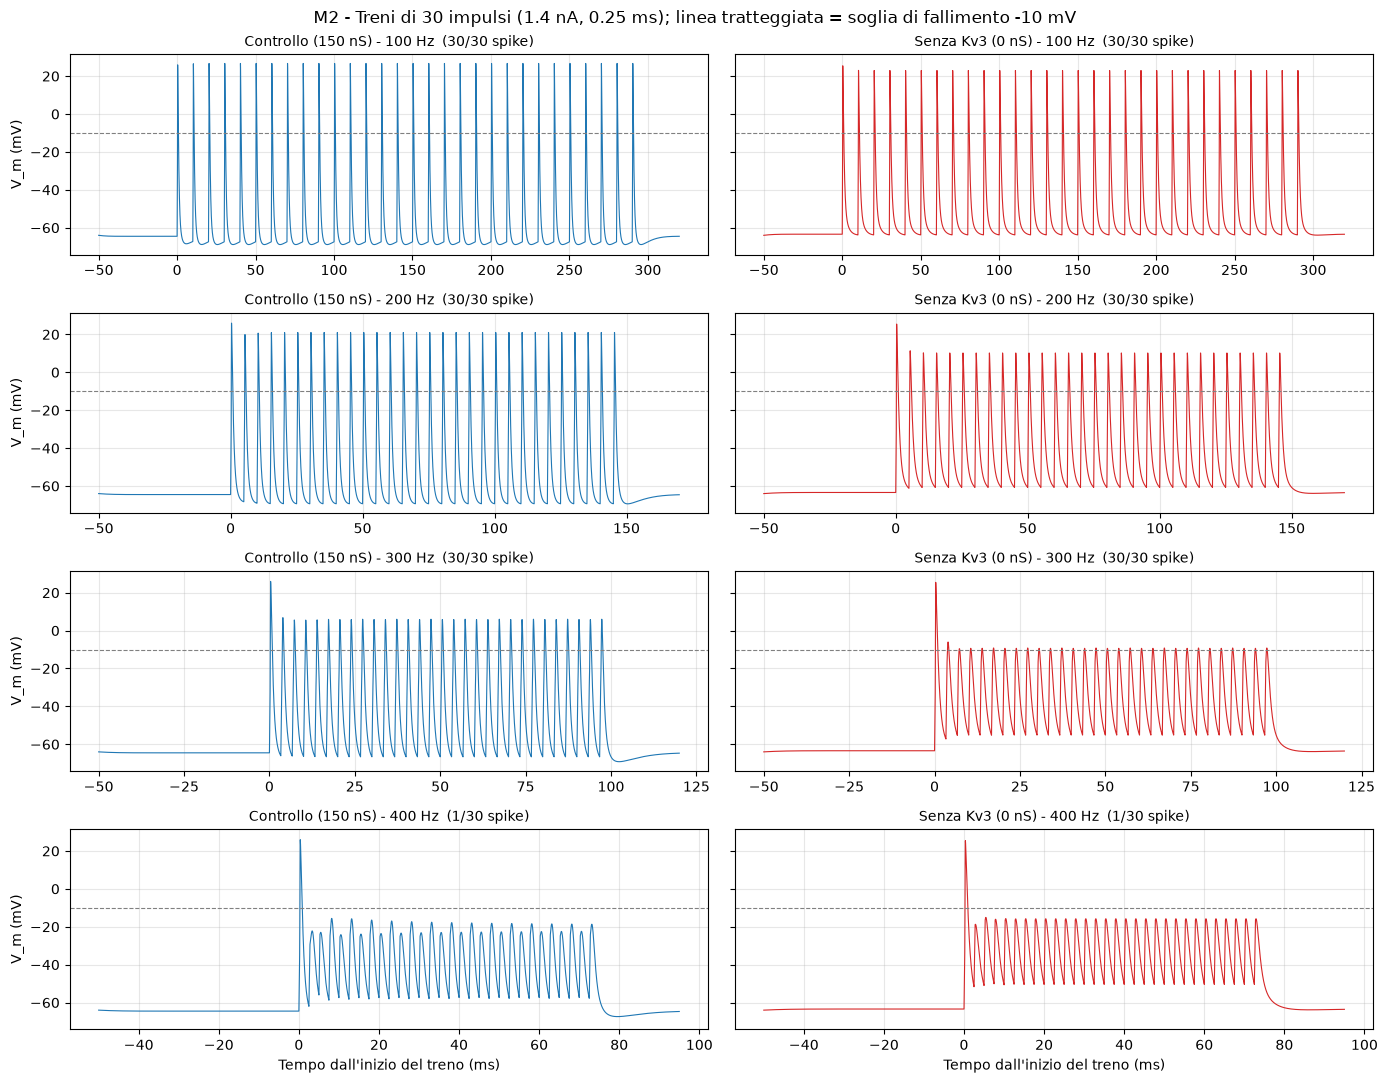

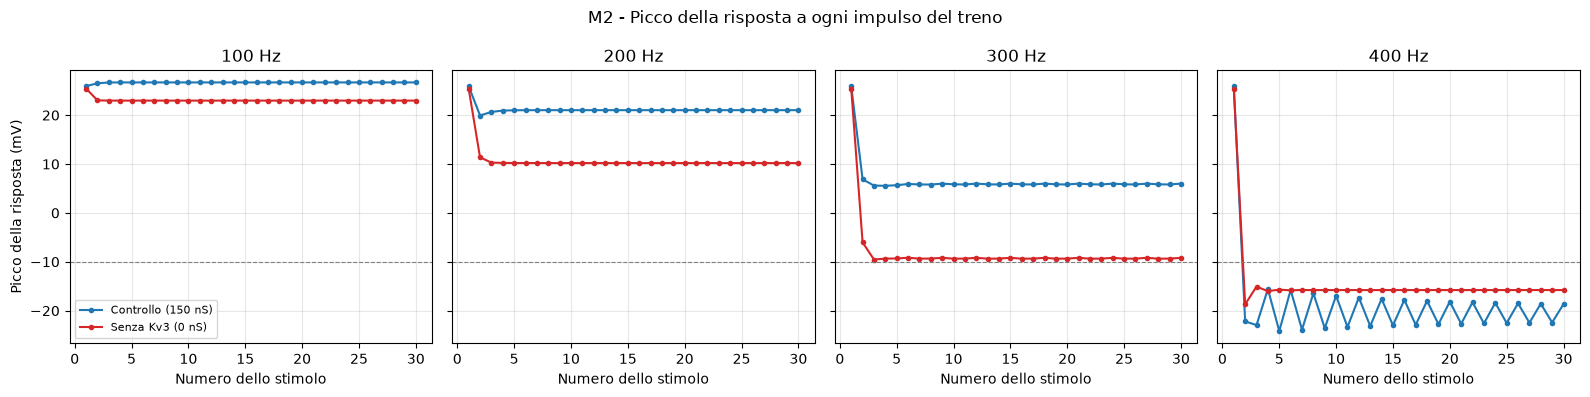

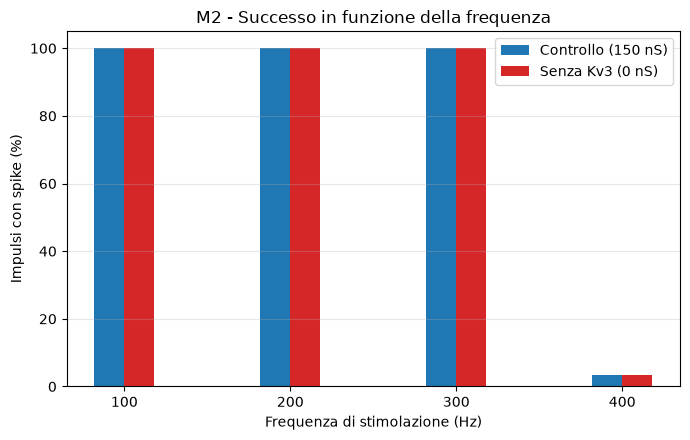

M2 - RIEPILOGO (spike riusciti su 30 impulsi)
 Frequenza    Controllo (150 nS)      Senza Kv3 (0 nS)
    100 Hz          30/30 (100%)          30/30 (100%)
    200 Hz          30/30 (100%)          30/30 (100%)
    300 Hz          30/30 (100%)          30/30 (100%)
    400 Hz             1/30 (3%)             1/30 (3%)
------------------------------------------------------------------
Atteso (Wang Fig. 5C-D): con Kv3 1:1 fino a ~300 Hz, failures a 400 Hz;
                         senza Kv3 segue fino a 200 Hz, sopra 300 Hz solo il primo spike.


In [2]:
# ============================================================
# M2 - Treni di impulsi con e senza Kv3
# ============================================================

frequencies = [100, 200, 300, 400]     # Hz
conditions = {"Controllo (150 nS)": 150.0, "Senza Kv3 (0 nS)": 0.0}
colors = {"Controllo (150 nS)": "tab:blue", "Senza Kv3 (0 nS)": "tab:red"}

n_pulses = 30
amplitude = 1400.0     # pA = 1.4 nA
pulse_width = 0.25     # ms
start_time = 50.0      # ms - attesa iniziale per arrivare al riposo
threshold = -10.0      # mV - criterio di fallimento (Macica)

results_M2 = {}

for label, g in conditions.items():
    for freq in frequencies:
        period = 1000.0 / freq
        amp_times, amp_values, onsets = [], [], []
        for i in range(n_pulses):
            t_on = round((start_time + i * period) / dt) * dt
            t_off = round((start_time + i * period + pulse_width) / dt) * dt
            amp_times += [t_on, t_off]
            amp_values += [amplitude, 0.0]
            onsets.append(t_on + dt)          # arrivo reale della corrente al neurone

        sim_time = round((start_time + n_pulses * period + 20.0) / dt) * dt
        t, V = run_simulation(amp_times, amp_values, sim_time, params={"g_Kv3": g})

        # Picco della risposta a ogni impulso (finestra: da questo impulso al successivo)
        peaks = []
        for i, t_on in enumerate(onsets):
            t_next = onsets[i + 1] if i < n_pulses - 1 else t_on + period
            mask = (t >= t_on) & (t < t_next)
            peaks.append(np.max(V[mask]))
        peaks = np.array(peaks)
        successes = int(np.sum(peaks >= threshold))

        results_M2[(label, freq)] = {"t": t, "V": V, "onsets": onsets, "peaks": peaks,
                                     "successes": successes}

# ------------------------------------------------------------
# Figura 1 - Tracce di tensione (righe = frequenze, colonne = condizioni)
# come Macica Fig. 1d-f e Wang Fig. 5C-D
# ------------------------------------------------------------
fig, axes = plt.subplots(len(frequencies), len(conditions), figsize=(14, 11), sharey=True)
for col, label in enumerate(conditions):
    for row, freq in enumerate(frequencies):
        r = results_M2[(label, freq)]
        ax = axes[row, col]
        ax.plot(r["t"] - start_time, r["V"], color=colors[label], linewidth=0.8)
        ax.axhline(threshold, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f'{label} - {freq} Hz  ({r["successes"]}/{n_pulses} spike)', fontsize=10)
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel("V_m (mV)")
        if row == len(frequencies) - 1:
            ax.set_xlabel("Tempo dall'inizio del treno (ms)")
fig.suptitle("M2 - Treni di 30 impulsi (1.4 nA, 0.25 ms); linea tratteggiata = soglia di fallimento -10 mV")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 2 - Ampiezza del picco stimolo per stimolo
# (mostra il calo "use-dependent" dell'ampiezza durante il treno)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, len(frequencies), figsize=(16, 4), sharey=True)
for ax, freq in zip(axes, frequencies):
    for label in conditions:
        r = results_M2[(label, freq)]
        ax.plot(np.arange(1, n_pulses + 1), r["peaks"], "o-", markersize=3,
                color=colors[label], label=label)
    ax.axhline(threshold, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(f"{freq} Hz")
    ax.set_xlabel("Numero dello stimolo")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Picco della risposta (mV)")
axes[0].legend(fontsize=8)
fig.suptitle("M2 - Picco della risposta a ogni impulso del treno")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 3 - Percentuale di successo in funzione della frequenza
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
width = 18
for k, label in enumerate(conditions):
    perc = [100.0 * results_M2[(label, f)]["successes"] / n_pulses for f in frequencies]
    x = np.array(frequencies) + (k - 0.5) * width
    ax.bar(x, perc, width=width, color=colors[label], label=label)
ax.set_xticks(frequencies)
ax.set_xlabel("Frequenza di stimolazione (Hz)")
ax.set_ylabel("Impulsi con spike (%)")
ax.set_ylim(0, 105)
ax.set_title("M2 - Successo in funzione della frequenza")
ax.grid(alpha=0.3, axis="y")
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Riepilogo numerico
# ------------------------------------------------------------
print("==================================================================")
print("M2 - RIEPILOGO (spike riusciti su 30 impulsi)")
print("==================================================================")
print(f"{'Frequenza':>10}" + "".join(f"{label:>22}" for label in conditions))
for freq in frequencies:
    row = f"{freq:>7} Hz"
    for label in conditions:
        s = results_M2[(label, freq)]["successes"]
        cell = str(s) + "/" + str(n_pulses) + " (" + format(100 * s / n_pulses, ".0f") + "%)"
        row += f"{cell:>22}"
    print(row)
print("------------------------------------------------------------------")
print("Atteso (Wang Fig. 5C-D): con Kv3 1:1 fino a ~300 Hz, failures a 400 Hz;")
print("                         senza Kv3 segue fino a 200 Hz, sopra 300 Hz solo il primo spike.")


## Come leggere i risultati

- **Figura 1** è da confrontare "a occhio" con Wang Fig. 5C-D e Macica Fig. 1d-f: stessa disposizione (frequenze in righe, condizioni in colonne).
- **Figura 2** mostra se gli spike si **rimpiccioliscono** durante il treno anche quando superano la soglia (il calo "use-dependent" che Wang descrive a 200 Hz senza Kv3).
- **Figura 3** riassume tutto in un numero per frequenza: è il confronto più diretto tra le due condizioni.
- Se la colonna "Controllo" fallisce già a 300 Hz (come visto in A1), il problema dello spike troppo largo (V2) si vede anche qui.
